In [1]:
# Core Libraries
import numpy as np
import pandas as pd
import re
import random

# PyTorch Core
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Keras Tokenizer (for vocab + padding)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Scikit-learn
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.utils import resample
from sklearn.svm import SVC, LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

# Plotting
import matplotlib.pyplot as plt
from itertools import cycle

# NLP
import nltk
from nltk.stem.snowball import SnowballStemmer

# Optional: Progress Bar
from tqdm import tqdm

# Transformers (optional if using BERT later)
from transformers import AutoModel
from transformers import AutoTokenizer


C:\Users\Administrator\anaconda3\envs\pytorchCU126_py310_new\lib\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


C:\Users\Administrator\anaconda3\envs\pytorchCU126_py310_new\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import re
from nltk.tokenize import word_tokenize

# Bengali stopwords (offline-safe)
bengali_stopwords = {
    "অনেক", "অন্য", "অবশ্য", "আগে", "আছে", "আজ", "আবার", "আমরা", "আমাদের", "আর",
    "ই", "উত্তর", "উপর", "উপরে", "এ", "এই", "এক্", "এখন", "এত", "এব", "এমন", "এমনি",
    "এর", "এস", "এসে", "ও", "ওই", "কমনে", "করা", "করে", "কাছে", "কাজ", "কাজে", "কারণ",
    "কি", "কিছু", "কে", "কেউ", "কেখা", "কেন", "কোটি", "কোনো", "কয়েক", "খুব", "গিয়ে",
    "গেল", "চার", "চালু", "চেষ্টা", "ছিল", "জানা", "জ্নজন", "টি", "তখন", "তবে", "তা",
    "তাই", "তো", "থাকা", "থেকে", "দিন", "দু", "দুই", "দেওয়া", "ধামার", "নতুন", "না",
    "নাগাদ", "নিয়ে", "নেওয়া", "নয়", "পর", "পরে", "পাচ", "পি", "পেয়্র্", "প্রতি", "প্রথম",
    "প্রযন্ত", "প্রাথমিক", "প্রায়", "বক্তব্য", "বন", "বলা", "বলে", "বলেন", "বহু", "বা",
    "বি", "বিভিন্ন", "বেশ", "বেশি", "মতো", "মধ্যে", "মনে", "যখন", "যদি", "যা", "যাওয়া",
    "যে", "র", "রকম", "লক্ষ", "শুধু", "শুরু", "সঙ্গে", "সব", "সহ", "সাধারণ", "সামনে",
    "সি", "সে", "সেই", "হতে", "হাজার", "হয়", "এই", "ও", "থেকে", "করে", "এ", "না", "ওই",
    "এক্", "নিয়ে", "করা", "বলেন", "সঙ্গে", "যে", "এব", "তা", "আর", "কোনো", "বলে", "সেই",
    "দিন", "হয়", "কি", "দু", "পরে", "সব", "দেওয়া", "মধ্যে", "এর", "সি", "শুরু", "কাজ",
    "কিছু", "কাছে", "সে", "তবে", "বা", "বন", "আগে", "জ্নজন", "পি", "পর", "তো", "ছিল",
    "এখন", "আমরা", "প্রায়", "দুই", "আমাদের", "তাই", "অন্য", "গিয়ে", "প্রযন্ত", "মনে",
    "নতুন", "মতো", "কেখা", "প্রথম", "আজ", "টি", "ধামার", "অনেক", "বিভিন্ন", "র", "হাজার",
    "জানা", "নয়", "অবশ্য", "বেশি", "এস", "করে", "কে", "হতে", "বি", "কয়েক", "সহ", "বেশ",
    "এমন", "এমনি", "কেন", "কেউ", "নেওয়া", "চেষ্টা", "লক্ষ", "বলা", "কারণ", "আছে", "শুধু",
    "তখন", "যা", "এসে", "চার", "ছিল", "যদি", "আবার", "কোটি", "উত্তর", "সামনে", "উপর",
    "বক্তব্য", "এত", "প্রাথমিক", "উপরে", "আছে", "প্রতি", "কাজে", "যখন", "খুব", "বহু",
    "গেল", "পেয়্র্", "চালু", "ই", "নাগাদ", "থাকা", "পাচ", "যাওয়া", "রকম", "সাধারণ", "কমনে",
    "অবশ্য", "অনেক", "অনেকে", "অনেকেই", "অন্তত", "অথবা", "অথচ", "অর্থাত", "অন্য", "আজ",
    "আছে", "আপনার", "আপনি", "আবার", "আমরা", "আমাকে", "আমাদের", "আমার", "আমি", "আরও",
    "আর", "আগে", "আগেই", "আই", "অতএব", "আগামী", "অবধি", "অনুযায়ী", "আদ্যভাগে", "এই",
    "একই", "একে", "একটি", "এখন", "এখনও", "এখানে", "এখানেই", "এটি", "এটা", "এটাই",
    "এতটাই", "এবং", "একবার", "এবার", "এদের", "এঁদের", "এমন", "এমনকী", "এল", "এর", "এরা",
    "এঁরা", "এস", "এত", "এতে", "এসে", "একে", "এ", "ঐ", "ই", "ইহা", "ইত্যাদি", "উনি", "উপর",
    "উপরে", "উচিত", "ও", "ওই", "ওর", "ওরা", "ওঁর", "ওঁরা", "ওকে", "ওদের", "ওঁদের", "ওখানে",
    "কত", "কবে", "করতে", "কয়েক", "কয়েকটি", "করবে", "করলেন", "করার", "কারও", "করা",
    "করি", "করিয়ে", "করার", "করাই", "করলে", "করলেন", "করিতে", "করিয়া", "করেছিলেন",
    "করছে", "করছেন", "করেছেন", "করেছে", "করেন", "করবেন", "করায়", "করে", "করেই", "কাছ",
    "কাছে", "কাজে", "কারণ", "কিছু", "কিছুই", "কিন্তু", "কিংবা", "কি", "কী", "কেউ",
    "কেউই", "কাউকে", "কেন", "কে", "কোনও", "কোনো", "কোন", "কখনও", "ক্ষেত্রে", "খুব",
    "গুলি", "গিয়ে", "গিয়েছে", "গেছে", "গেল", "গেলে", "গোটা", "চলে", "ছাড়া", "ছাড়াও",
    "ছিলেন", "ছিল", "জন্য", "জানা", "ঠিক", "তিনি", "তিনঐ", "তিনিও", "তখন", "তবে", "তবু",
    "তাঁদের", "তাঁাহারা", "তাঁরা", "তাঁর", "তাঁকে", "তাই", "তেমন", "তাকে", "তাহা", "তাহাতে",
    "তাহার", "তাদের", "তারপর", "তারা", "তারৈ", "তার", "তাহলে", "তিনি", "তা", "তাও", "তাতে",
    "তো", "তত", "তুমি", "তোমার", "তথা", "থাকে", "থাকা", "থাকায়", "থেকে", "থেকেও", "থাকবে",
    "থাকেন", "থাকবেন", "থেকেই", "দিকে", "দিতে", "দিয়ে", "দিয়েছে", "দিয়েছেন", "দিলেন",
    "দু", "দুটি", "দুটো", "দেয়", "দেওয়া", "দেওয়ার", "দেখা", "দেখে", "দেখতে", "দ্বারা",
    "ধরে", "ধরা", "নয়", "নানা", "না", "নাকি", "নাগাদ", "নিতে", "নিজে", "নিজেই", "নিজের",
    "নিজেদের", "নিয়ে", "নেওয়া", "নেওয়ার", "নেই", "নাই", "পক্ষে", "পর্যন্ত", "পাওয়া",
    "পারেন", "পারি", "পারে", "পরে", "পরেই", "পরেও", "পর", "পেয়ে", "প্রতি", "প্রভৃতি",
    "প্রায়", "ফের", "ফলে", "ফিরে", "ব্যবহার", "বলতে", "বললেন", "বলেছেন", "বলল", "বলা",
    "বলেন", "বলে", "বহু", "বসে", "বার", "বা", "বিনা", "বরং", "বদলে", "বাদে", "বার", "বিশেষ",
    "বিভিন্ন", "বিষয়টি", "ব্যবহার", "ব্যাপারে", "ভাবে", "ভাবেই", "মধ্যে", "মধ্যেই",
    "মধ্যেও", "মধ্যভাগে", "মাধ্যমে", "মাত্র", "মতো", "মতোই", "মোটেই", "যখন", "যদি",
    "যদিও", "যাবে", "যায়", "যাকে", "যাওয়া", "যাওয়ার", "যত", "যতটা", "যা", "যার", "যারা",
    "যাঁর", "যাঁরা", "যাদের", "যান", "যাচ্ছে", "যেতে", "যাতে", "যেন", "যেমন", "যেখানে",
    "যিনি", "যে", "রেখে", "রাখা", "রয়েছে", "রকম", "শুধু", "সঙ্গে", "সঙ্গেও", "সমস্ত",
    "সব", "সবার", "সহ", "সুতরাং", "সহিত", "সেই", "সেটা", "সেটি", "সেটাই", "সেটাও",
    "সম্প্রতি", "সেখান", "সেখানে", "সে", "স্পষ্ট", "স্বয়ং", "হইতে", "হইবে", "হৈলে",
    "হইয়া", "হচ্ছে", "হত", "হতে", "হতেই", "হবে", "হবেন", "হয়েছিল", "হয়েছে", "হয়েছেন",
    "হয়ে", "হয়নি", "হয়", "হয়েই", "হয়তো", "হল", "হলে", "হলেই", "হলেও", "হলো", "হিসাবে",
    "হওয়া", "হওয়ার", "হওয়ায়", "হন", "হোক", "জন", "জনকে", "জনের", "জানতে", "জানায়",
    "জানিয়ে", "জানানো", "জানিয়েছে", "জন্য", "জন্যওজে", "জে", "বেশ", "দেন", "তুলে",
    "ছিলেন", "চান", "চায়", "চেয়ে", "মোট", "যথেষ্ট", "টি"
}

bn_sw = bengali_stopwords

# Rule-based pseudo stemmer
def basic_bengali_stemmer(word):
    suffixes = [
        'গুলো', 'গুলি', 'টাকে', 'টিতে', 'টায়', 'টা', 'টি',
        'দেরকে', 'দের', 'গুলোকে', 'কে', 'তে', 'তা', 'ের', 'েন',
        'ছি', 'ছিল', 'বেন', 'েছ', 'ে', 'রা', 'য়'
    ]
    for suffix in suffixes:
        if word.endswith(suffix) and len(word) > len(suffix) + 1:
            return word[:-len(suffix)]
    return word

# Cleaning functions
def remove_url(text):
    return re.sub(r"(?:\@|https?\://)\S+", "", text) if isinstance(text, str) else ''

def remove_numbers(text):
    return re.sub(r'\d+', '', text) if isinstance(text, str) else ''

def remove_english(text):
    return re.sub(r'[a-z]', '', text) if isinstance(text, str) else ''

def remove_short_words(text, min_len=2):
    if not isinstance(text, str):
        return ''
    return ' '.join([word for word in text.split() if len(word) >= min_len])

def remove_repeated_punctuation(text):
    return re.sub(r'[\?\.\!\।]+(?=[\?\.\!\।])', '', text) if isinstance(text, str) else ''

def remove_extra_whitespace(text):
    return ' '.join(text.split()) if isinstance(text, str) else ''

def remove_dari(text):
    return re.sub(r'।', '', text) if isinstance(text, str) else ''

def remove_bengali_stopwords(text):
    if not isinstance(text, str):
        return ''
    return ' '.join([word for word in text.split() if word not in bengali_stopwords])

# Final cleaner
def clean_comment(text):
    if not isinstance(text, str):
        return ''
    text = text.lower()
    text = remove_url(text)
    text = remove_english(text)
    text = remove_dari(text)
    text = remove_numbers(text)
    text = remove_short_words(text)
    text = remove_repeated_punctuation(text)
    text = remove_extra_whitespace(text)
    words = text.split()
    # Remove stopwords and apply stemming
    cleaned = [basic_bengali_stemmer(word) for word in words if word not in bengali_stopwords]
    return ' '.join(cleaned)

label_encoder = LabelEncoder()

In [3]:
# Define positive Bengali words
positive_words = {
    "অসাধারণ", "দারুণ", "চমৎকার", "অবিশ্বাস্য", "সুন্দর", "অত্যন্ত ভালো", "অভিনন্দন", "শ্রদ্ধা", "প্রশংসনীয়", "মুগ্ধ",
    "দারুণ কাজ", "ভালোবাসা", "অনন্য", "সেরা", "জয় হোক", "অনবদ্য", "অপূর্ব", "অতুলনীয়", "আকর্ষণীয়", "অনিন্দ্য",
    "উজ্জ্বল", "উচ্ছ্বাস", "উত্তম", "উত্সাহজনক", "উজ্জীবিত", "উন্নত", "একেবারে অসাধারণ", "একান্ত ভালো", "আনন্দদায়ক",
    "আশ্চর্যজনক", "আশার আলো", "অর্জন", "আলোকিত", "আশা জাগানো", "কৃতজ্ঞতা", "খাঁটি", "খুশি", "গর্বিত", "গুণগত",
    "গৌরবজনক", "যথার্থ", "চিত্তাকর্ষক", "জয়ী", "দৃঢ়", "দীপ্ত", "দৃষ্টিনন্দন", "দয়ালু", "নান্দনিক", "নিখুঁত",
    "নিবেদিত", "প্রশান্তি", "প্রশস্ত", "প্রেরণাদায়ক", "ফলপ্রসূ", "বেড়ে চলা", "মহৎ", "মনোমুগ্ধকর", "মধুর", "মিষ্টি",
    "মজাদার", "মহান", "মার্জিত", "রহস্যময়", "লোভনীয়", "লাবণ্য", "শ্রেষ্ঠ", "স্বপ্নিল", "স্বর্ণালী", "স্নিগ্ধ",
    "সৃষ্টিশীল", "স্মরণীয়", "সমৃদ্ধ", "সাবলীল", "সত্য", "হৃদয়স্পর্শী", "হালকা", "হীরক", "হিরণ্ময়", "হংস"
}
negative_words = {
    # Religious Hate
    "মন্দির ভাঙো", "মসজিদ ধ্বংস", "জিহাদ", "কাফের", "ধর্মান্তর", "পূজা বন্ধ",
    "ধর্মের অপমান", "নাস্তিক", "ধর্মদ্রোহী", "খ্রিস্টান কুকুর", "হিন্দু কুকুর",
    "বৌদ্ধ নষ্ট", "ধর্ম যুদ্ধ", "ধর্মের শত্রু", "ধর্মের নামে হিংসা", "মুসলিম কুকুর",
    "ধর্ম ছাড়", "পাপী", "নরকগামী",  
    # General Hate/Abuse
    "গালি", "অপমান", "ঘৃণা", "শত্রু", "মারধর", "খুন", "জল্লাদ", "হত্যা", "ধর্ষণ",
    "নষ্ট", "কুত্তার বাচ্চা", "হারামি", "বেশ্যা", "অসভ্য", "নিচ", "জঘন্য", "পাষণ্ড",
    "অপদার্থ", "নরাধম", "কম্বক্ত", "গাধা", "মূর্খ", "পাজি", "অধম", "শয়তান", "চোর",
    "বদমাশ", "অপকর্মী",  
    # Threats/Violence
    "মেরে ফেলব", "খুন করব", "পিটিয়ে মারব", "জ্যান্ত পুড়িয়ে মারব", "ঘর থেকে তাড়াব",
    "ধরাশায়ী করব", "রক্ত ঝরাব", "বোমা মারব", "গলা কাটব", "পাথর মারব", "জীবন নষ্ট করব",
    "মাথা ফাটব", "হাড় ভাঙব", "চোখ তুলব",  
    # Gender/Caste Slurs
    "দলিত কুকুর", "নীচ জাত", "মেয়েলি গালি", "স্ত্রীজাত", "অস্পৃশ্য", "জাত খারাপ",
    "কুলটা", "রাঁড়", "বেশ্যার পুত্র", "হরিজন", "জাতিচ্যুত", "গোয়ালার বাচ্চা",
    "চামার",  
    # Sexual/Explicit Content
    "যৌন", "অশ্লীল", "গুদা", "চোদা", "ভোগ", "ধোন", "মাই চুষ", "বস্তা", "মাগি",
    "খানকি",  
    # Cyberbullying/Trolling
    "মর বাচ্চা", "বোকাচোদা", "টিটকারি", "তোর বাপের ব্যাটা", "খান্কি মাগি",
    "বুদ্ধি নষ্ট", "মুখে থু", "লান্ড চুষ", "চোদনা", "হাঁড়িচ্যাটা",
    "শুয়োরের বাচ্চা", "কুত্তার বাচ্ছা", "হারামির বাচ্চা", "হারামি", "হারামজাদা", "হারামখোর", 
    "খাঙ্কিরপোলা", "খান্কি মাগির পোলা", "চোদনা", "চুদির ভাই", "চুতমারানি", "চুদির পোলা", 
    "তর মায়রে চুদি", "তর মায়রে বাপ", "শালা", "শালার পো শালা", "হুমুন্দির পুত", "মাঙ্গির পুত", 
    "নাটকির পো", "ল্যাউড়ার পুত", "হাউয়ার পো", "হাউয়ার নাতি", "চুদানির পো", "ভুদার বেটা", 
    "লটির পো", "লটির বেটা", "ভেড়াচ্চোদা", "মাউড়া চোদা", "গুয়ার ভিতরে ভইড়া দিমু", 
    "হোগার ভিতরে ভইড়া দিমু", "ঠ্যাঁঙ কাইট্টা পুটকি দা ভইরা দুম!", "হালা ল্যাওড়া চোদা", "বানচোত", 
    "কুত্তাচোদা", "তর পুটকিত ধান ছড়াইয়া চড়ুই দিয়া খাওয়ামু", "পুটকি", "বালি দিয়া চুদমু তরে খাঙ্কি মাগী!", 
    "চুদমু", "বালের রয়েল বেঙ্গল উকুন", "বাল", "তোর হউরিরে ডিগবাজী", "ছি ছি ছি", 
    "তোর জাঙ্গীয়া খুইল্যা আগুন লাগায় দিমু", "বাল ফালায়া খালে নামানো", "বাল ফালায়া আটিঁ বান্ধা", 
    "বালে বালে গিট্টু", "গোলাম আযম", "মইত্যা নিজামী", "গেলমান", "তিনকোনা", "চতুরচোর", 
    "মহাবুবস্", "বাপের আগে বাল ফালায়", "ভোদাই", "ভোদার বাল", "বাল", "বাল ছাল", "ধোনের বাল",
    "ধোন", "হোল", "টেংরি ভাইংগা হাতে ধরায়া দিমু", "নটি", "নটি মাগি", "মাগি", "নটি মাগির পোলা", 
    "নটি মাগির ঝি", "গুদের বাল", "মাগিবাজ", "মাইগ্যা", "বারবাতারি", "বেশ্যা", "বেশ্যা মাগী", 
    "বাল ফালাইয়া আটি বান", "ভৈরব মাগী", "পুকটি মারা খা", "পুকটি", "পুক্টি", "গাড় মারা খা", 
    "ভইরা দিমু", "মাঙ্গের পোলা", "উপ্তা কইরা চুদমু", "মাঙ্গের নাতি", "চুদনা মাগী", "ভাতার চুদা", 
    "মীরজাফর", "নীজামী", "উপ্তা কইরা চুদা দিমু", "গোস্তের লাঠি সাটামু", "ধোন কাইট্টা কুত্তা দিয়া খাওয়ামু", 
    "কুত্তা", "কুত্তার বাচ্চা", "লেওরা", "নিবীর্জ", "চুতমারানীর পোলা", "তর মায়েরে চিচিং ফাক", "কান্দে ফালাইয়া তর মায়েরে চুদি", "পুটকিতে বাশ দিমু", "চামড়া ছুইল্লা লবণ লাগামু", "লাথ্থি দিমু", "উষ্টা খা", "সুদখোর", "গুদির ব্যাটা", "কাঠ্ঠির বেট্যা", "ল্যাদানী", "হোলচাটা", "মাহফুজ সাহেব", "বাইনচোদ", "মাদার চোদ", "হোগা চাটা", "নিজামী চোদা", "মুজাহিদের বউ", "বটই", "পেল", "গো আর জুতা", "শাউয়া", "কুত্তার হোল", "হোল টাইনা পুকটিতে ভর", "হোলের চুলকানী", "আবাল চোদা", "চোদ", "বোকা আচোদা", "খবিশ চোদা", "খবিশ", "ভুস্কি মাগির পোলা", "তর ভোদায় বিলাই হ্যাচড়া", "তর মার ভোদায়", "তর মায়ের ভুদাতে পোকা", "তর বাপপের হোল তর বউয়ের ভোদাতে", "তর মায়ের ঐখানে বিছাতু পাতা", "গোলাম আযম", "হিটলার", "মজবাশার", "তোগোরে ফাসিতে লটকাইয়া চুদমু", "তোগোর ধোন টাইনা তোগোর পিছন দিয়া ঢুকামু", "জং ধরা লোহা দিয়া পাকিস্তানের মানচিত্র বানাই্য়া তোদের পিছন দিয়া ঢুকামু", "তর মায়ের ভোদা শিরিষ কাগজ দিয়া ঘইষা দিমু", "তর মায়ের ভোদা বোম্বাই মরিচ দিয়া চুদামু", "তর হোগায় ইনপুট", "তর মায়ের ভোদায় আউটপুট", "তর বাপের পুটকির ফুটা দিয়া কাডল ঢুকামু", "নিজামীর গোয়ার কৃমি", "তর বাপের ধন দিয়া ডাংগুলি খেলুম", "তর বাপের বিচি বেইচা কটকটি খামু", "তর বৌয়ের ভোদায় মাগুর মাছ চাষ করুম", "তর ধন দিয়া মাটি খুড়ুম", "ফাটা কন্ডমের ফসল", "লাত্থায় তর মার আনরেজিস্টার্ড শ্বশুরবাড়ী ফাকিস্তান পাঠায় দিমু", "হাতির ল্যাওড়া দিয়া তর মায়েরে চুদুম", "তর মায়ের ভোদা ছিল্লা লবণ লাগায় দিমু", "তর বাপের হোগা দিয়া ট্রেন ভইরা দিমু", "তরে গোআ দিয়া চুদামু", "এক কানে হোল ভইরা আরেক কান দিয়া বাইর করমু", "তোর হোল ভাজি কইরা তোরেই খাওয়ামু", "কুত্তার পুকটি চাটামু", "মাসিকের ত্যানা", "তোর নাকে হাইগ্যা দিমু", "হাইগ্যা", "তোর বাপ গাইড়্যা", "মোবাইল ভাইব্রেশন কইরা তুর পুকটিতে ভরবো", "তোর বাপে তোর নানা", "তোর বউয়ের মুসলমানি দিমু", "বদমায়েশ", "অপমান", "গালি", "ধর্ষক", "হত্যাকারী", "খারাপ মন্তব্য"
}

# Function to check for positive words
def is_positive(comment):
    return any(word in comment for word in positive_words)

# Function to check for negative words
def is_negative(comment):
    return any(word in comment for word in negative_words)

# Custom Methods
def classify_sentiment(row):
    if row['category'] == 1:
        return 'negative'
    elif is_negative(row['comment']):
        return 'negative'
    elif is_positive(row['comment']):
        return 'positive'
    else:
        return 'neutral'

# Load existing datasets
# --- Dataset 1: bangla_online_comments_dataset.csv ---
df1 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/bangla_online_comments_dataset.csv')
df1 = df1.rename(columns={'comment': 'comment', 'label': 'category'})[['comment', 'category']]
df1['comment'] = df1['comment'].astype(str).fillna('').str.strip()

df1['is_positive'] = df1['comment'].apply(is_positive)
df1['is_negative'] = df1['comment'].apply(is_negative)

conditions = [
    (df1['category'] == 'not bully') & df1['is_positive'],
    (df1['category'] == 'not bully') & ~df1['is_positive'],
    (df1['category'].isin(['troll', 'religious'])) & ~df1['is_negative']
]
choices = [
    'positive',  # Condition 1
    'neutral',   # Condition 2
    'neutral'    # Condition 3
]
df1['sentiment'] = np.select(conditions, choices, default='negative')  # Fallback to negative
df1 = df1[df1['sentiment'].isin(['positive', 'negative'])].reset_index(drop=True)

# --- Dataset 2: Bengali hate speech.csv ---
df2 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/Bengali hate speech.csv')
df2 = df2[['sentence', 'hate']]
df2 = df2.rename(columns={'sentence': 'comment', 'hate': 'category'})[['comment', 'category']]
df2['comment'] = df2['comment'].astype(str).fillna('').str.strip()

# Apply classification
df2['sentiment'] = df2.apply(classify_sentiment, axis=1)
df2 = df2[df2['sentiment'].isin(['positive', 'negative'])].reset_index(drop=True)

# --- Dataset 3: bdsh_train.csv ---
df3 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/bdsh_train.csv')
df3 = df3.rename(columns={
    'sentence': 'comment',
    'hate speech': 'category'
})[['comment', 'category']]
df3['comment'] = df3['comment'].astype(str).fillna('').str.strip()

# Apply classification
df3['sentiment'] = df3.apply(classify_sentiment, axis=1)
df3 = df3[df3['sentiment'].isin(['positive', 'negative'])].reset_index(drop=True)

# Load SentNoB dataset
df4 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/SentNoB_train.csv')
df4 = df4.rename(columns={
    'Data': 'comment',
    'Label': 'category'
})[['comment', 'category']]

df4['comment'] = df4['comment'].astype(str).fillna('').str.strip()

# Map numerical labels to sentiments
label_mapping = {0: 'neutral', 1: 'positive', 2: 'negative'}
df4['sentiment'] = df4['category'].map(label_mapping)
df4 = df4[df4['sentiment'].isin(['positive', 'negative'])].reset_index(drop=True)

# Load the Saqib dataset
df5 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/saqib-data-merged.csv')
df5 = df5.rename(columns={
    'text': 'comment',
    'sentiment': 'sentiment'
})[['comment', 'sentiment']]

df5['comment'] = df5['comment'].astype(str).fillna('').str.strip()
df5 = df5[df5['sentiment'].isin(['positive', 'negative'])].reset_index(drop=True)

# --- Dataset 6: collected.csv ---
df6 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/collected.csv')
df6 = df6.rename(columns={
    'sentence': 'comment',
    'hate speech': 'category'
})[['comment', 'category']]
df6['comment'] = df6['comment'].astype(str).fillna('').str.strip()

# Apply classification
df6['sentiment'] = df6.apply(classify_sentiment, axis=1)
df6 = df6[df6['sentiment'].isin(['positive', 'negative'])].reset_index(drop=True)

# Ensure final cleaned versions with consistent columns
df1_final = df1[['comment', 'sentiment']]
df2_final = df2[['comment', 'sentiment']]
df3_final = df3[['comment', 'sentiment']]
df4_final = df4[['comment', 'sentiment']]
df5_final = df5[['comment', 'sentiment']]
df6_final = df6[['comment', 'sentiment']]

# Merge all datasets
merged_df = pd.concat([
    df1_final,
    df2_final,
    df3_final,
    df4_final,
    df5_final,
    df6_final
], ignore_index=True)

# Drop rows with missing values in key columns (just in case)
merged_df.dropna(subset=['comment', 'sentiment'], inplace=True)

merged_df = merged_df.rename(columns={
    'comment': 'comment',
    'sentiment': 'category'
})[['comment', 'category']]

# Save merged dataset
merged_df.to_csv("C:/Users/Administrator/Cyberbullying/FinalThesis/Dataset/raw_comments_PN.csv", index=False)
print("✅ Final dataset merged and saved as 'raw_comments_PN.csv'")

✅ Final dataset merged and saved as 'raw_comments_PN.csv'


In [4]:
# # Using two dataset
# # Define positive Bengali words
# positive_words = {
#     "অসাধারণ", "দারুণ", "চমৎকার", "অবিশ্বাস্য", "সুন্দর", "অত্যন্ত ভালো", "অভিনন্দন", "শ্রদ্ধা", "প্রশংসনীয়", "মুগ্ধ",
#     "দারুণ কাজ", "ভালোবাসা", "অনন্য", "সেরা", "জয় হোক", "অনবদ্য", "অপূর্ব", "অতুলনীয়", "আকর্ষণীয়", "অনিন্দ্য",
#     "উজ্জ্বল", "উচ্ছ্বাস", "উত্তম", "উত্সাহজনক", "উজ্জীবিত", "উন্নত", "একেবারে অসাধারণ", "একান্ত ভালো", "আনন্দদায়ক",
#     "আশ্চর্যজনক", "আশার আলো", "অর্জন", "আলোকিত", "আশা জাগানো", "কৃতজ্ঞতা", "খাঁটি", "খুশি", "গর্বিত", "গুণগত",
#     "গৌরবজনক", "যথার্থ", "চিত্তাকর্ষক", "জয়ী", "দৃঢ়", "দীপ্ত", "দৃষ্টিনন্দন", "দয়ালু", "নান্দনিক", "নিখুঁত",
#     "নিবেদিত", "প্রশান্তি", "প্রশস্ত", "প্রেরণাদায়ক", "ফলপ্রসূ", "বেড়ে চলা", "মহৎ", "মনোমুগ্ধকর", "মধুর", "মিষ্টি",
#     "মজাদার", "মহান", "মার্জিত", "রহস্যময়", "লোভনীয়", "লাবণ্য", "শ্রেষ্ঠ", "স্বপ্নিল", "স্বর্ণালী", "স্নিগ্ধ",
#     "সৃষ্টিশীল", "স্মরণীয়", "সমৃদ্ধ", "সাবলীল", "সত্য", "হৃদয়স্পর্শী", "হালকা", "হীরক", "হিরণ্ময়", "হংস"
# }
# negative_words = {
#     # Religious Hate
#     "মন্দির ভাঙো", "মসজিদ ধ্বংস", "জিহাদ", "কাফের", "ধর্মান্তর", "পূজা বন্ধ",
#     "ধর্মের অপমান", "নাস্তিক", "ধর্মদ্রোহী", "খ্রিস্টান কুকুর", "হিন্দু কুকুর",
#     "বৌদ্ধ নষ্ট", "ধর্ম যুদ্ধ", "ধর্মের শত্রু", "ধর্মের নামে হিংসা", "মুসলিম কুকুর",
#     "ধর্ম ছাড়", "পাপী", "নরকগামী",  
#     # General Hate/Abuse
#     "গালি", "অপমান", "ঘৃণা", "শত্রু", "মারধর", "খুন", "জল্লাদ", "হত্যা", "ধর্ষণ",
#     "নষ্ট", "কুত্তার বাচ্চা", "হারামি", "বেশ্যা", "অসভ্য", "নিচ", "জঘন্য", "পাষণ্ড",
#     "অপদার্থ", "নরাধম", "কম্বক্ত", "গাধা", "মূর্খ", "পাজি", "অধম", "শয়তান", "চোর",
#     "বদমাশ", "অপকর্মী",  
#     # Threats/Violence
#     "মেরে ফেলব", "খুন করব", "পিটিয়ে মারব", "জ্যান্ত পুড়িয়ে মারব", "ঘর থেকে তাড়াব",
#     "ধরাশায়ী করব", "রক্ত ঝরাব", "বোমা মারব", "গলা কাটব", "পাথর মারব", "জীবন নষ্ট করব",
#     "মাথা ফাটব", "হাড় ভাঙব", "চোখ তুলব",  
#     # Gender/Caste Slurs
#     "দলিত কুকুর", "নীচ জাত", "মেয়েলি গালি", "স্ত্রীজাত", "অস্পৃশ্য", "জাত খারাপ",
#     "কুলটা", "রাঁড়", "বেশ্যার পুত্র", "হরিজন", "জাতিচ্যুত", "গোয়ালার বাচ্চা",
#     "চামার",  
#     # Sexual/Explicit Content
#     "যৌন", "অশ্লীল", "গুদা", "চোদা", "ভোগ", "ধোন", "মাই চুষ", "বস্তা", "মাগি",
#     "খানকি",  
#     # Cyberbullying/Trolling
#     "মর বাচ্চা", "বোকাচোদা", "টিটকারি", "তোর বাপের ব্যাটা", "খান্কি মাগি",
#     "বুদ্ধি নষ্ট", "মুখে থু", "লান্ড চুষ", "চোদনা", "হাঁড়িচ্যাটা",
#     "শুয়োরের বাচ্চা", "কুত্তার বাচ্ছা", "হারামির বাচ্চা", "হারামি", "হারামজাদা", "হারামখোর", "খাঙ্কিরপোলা", "খান্কি মাগির পোলা", "চোদনা", "চুদির ভাই", "চুতমারানি", "চুদির পোলা", "তর মায়রে চুদি", "তর মায়রে বাপ", "শালা", "শালার পো শালা", "হুমুন্দির পুত", "মাঙ্গির পুত", "নাটকির পো", "ল্যাউড়ার পুত", "হাউয়ার পো", "হাউয়ার নাতি", "চুদানির পো", "ভুদার বেটা", "লটির পো", "লটির বেটা", "ভেড়াচ্চোদা", "মাউড়া চোদা", "গুয়ার ভিতরে ভইড়া দিমু", "হোগার ভিতরে ভইড়া দিমু", "ঠ্যাঁঙ কাইট্টা পুটকি দা ভইরা দুম!", "হালা ল্যাওড়া চোদা", "বানচোত", "কুত্তাচোদা", "তর পুটকিত ধান ছড়াইয়া চড়ুই দিয়া খাওয়ামু", "পুটকি", "বালি দিয়া চুদমু তরে খাঙ্কি মাগী!", "চুদমু", "বালের রয়েল বেঙ্গল উকুন", "বাল", "তোর হউরিরে ডিগবাজী", "ছি ছি ছি", "তোর জাঙ্গীয়া খুইল্যা আগুন লাগায় দিমু", "বাল ফালায়া খালে নামানো", "বাল ফালায়া আটিঁ বান্ধা", "বালে বালে গিট্টু", "গোলাম আযম", "মইত্যা নিজামী", "গেলমান", "তিনকোনা", "চতুরচোর", "মহাবুবস্", "বাপের আগে বাল ফালায়", "ভোদাই", "ভোদার বাল", "বাল", "বাল ছাল", "ধোনের বাল", "ধোন", "হোল", "টেংরি ভাইংগা হাতে ধরায়া দিমু", "নটি", "নটি মাগি", "মাগি", "নটি মাগির পোলা", "নটি মাগির ঝি", "গুদের বাল", "মাগিবাজ", "মাইগ্যা", "বারবাতারি", "বেশ্যা", "বেশ্যা মাগী", "বাল ফালাইয়া আটি বান", "ভৈরব মাগী", "পুকটি মারা খা", "পুকটি", "পুক্টি", "গাড় মারা খা", "ভইরা দিমু", "মাঙ্গের পোলা", "উপ্তা কইরা চুদমু", "মাঙ্গের নাতি", "চুদনা মাগী", "ভাতার চুদা", "মীরজাফর", "নীজামী", "উপ্তা কইরা চুদা দিমু", "গোস্তের লাঠি সাটামু", "ধোন কাইট্টা কুত্তা দিয়া খাওয়ামু", "কুত্তা", "কুত্তার বাচ্চা", "লেওরা", "নিবীর্জ", "চুতমারানীর পোলা", "তর মায়েরে চিচিং ফাক", "কান্দে ফালাইয়া তর মায়েরে চুদি", "পুটকিতে বাশ দিমু", "চামড়া ছুইল্লা লবণ লাগামু", "লাথ্থি দিমু", "উষ্টা খা", "সুদখোর", "গুদির ব্যাটা", "কাঠ্ঠির বেট্যা", "ল্যাদানী", "হোলচাটা", "মাহফুজ সাহেব", "বাইনচোদ", "মাদার চোদ", "হোগা চাটা", "নিজামী চোদা", "মুজাহিদের বউ", "বটই", "পেল", "গো আর জুতা", "শাউয়া", "কুত্তার হোল", "হোল টাইনা পুকটিতে ভর", "হোলের চুলকানী", "আবাল চোদা", "চোদ", "বোকা আচোদা", "খবিশ চোদা", "খবিশ", "ভুস্কি মাগির পোলা", "তর ভোদায় বিলাই হ্যাচড়া", "তর মার ভোদায়", "তর মায়ের ভুদাতে পোকা", "তর বাপপের হোল তর বউয়ের ভোদাতে", "তর মায়ের ঐখানে বিছাতু পাতা", "গোলাম আযম", "হিটলার", "মজবাশার", "তোগোরে ফাসিতে লটকাইয়া চুদমু", "তোগোর ধোন টাইনা তোগোর পিছন দিয়া ঢুকামু", "জং ধরা লোহা দিয়া পাকিস্তানের মানচিত্র বানাই্য়া তোদের পিছন দিয়া ঢুকামু", "তর মায়ের ভোদা শিরিষ কাগজ দিয়া ঘইষা দিমু", "তর মায়ের ভোদা বোম্বাই মরিচ দিয়া চুদামু", "তর হোগায় ইনপুট", "তর মায়ের ভোদায় আউটপুট", "তর বাপের পুটকির ফুটা দিয়া কাডল ঢুকামু", "নিজামীর গোয়ার কৃমি", "তর বাপের ধন দিয়া ডাংগুলি খেলুম", "তর বাপের বিচি বেইচা কটকটি খামু", "তর বৌয়ের ভোদায় মাগুর মাছ চাষ করুম", "তর ধন দিয়া মাটি খুড়ুম", "ফাটা কন্ডমের ফসল", "লাত্থায় তর মার আনরেজিস্টার্ড শ্বশুরবাড়ী ফাকিস্তান পাঠায় দিমু", "হাতির ল্যাওড়া দিয়া তর মায়েরে চুদুম", "তর মায়ের ভোদা ছিল্লা লবণ লাগায় দিমু", "তর বাপের হোগা দিয়া ট্রেন ভইরা দিমু", "তরে গোআ দিয়া চুদামু", "এক কানে হোল ভইরা আরেক কান দিয়া বাইর করমু", "তোর হোল ভাজি কইরা তোরেই খাওয়ামু", "কুত্তার পুকটি চাটামু", "মাসিকের ত্যানা", "তোর নাকে হাইগ্যা দিমু", "হাইগ্যা", "তোর বাপ গাইড়্যা", "মোবাইল ভাইব্রেশন কইরা তুর পুকটিতে ভরবো", "তোর বাপে তোর নানা", "তোর বউয়ের মুসলমানি দিমু", "বদমায়েশ", "অপমান", "গালি", "ধর্ষক", "হত্যাকারী", "খারাপ মন্তব্য"
# }

# # Function to check for positive words
# def is_positive(comment):
#     return any(word in comment for word in positive_words)

# # Function to check for negative words
# def is_negative(comment):
#     return any(word in comment for word in negative_words)

# # Custom Methods
# def classify_sentiment(row):
#     if row['category'] == 1:
#         return 'negative'
#     elif is_negative(row['comment']):
#         return 'negative'
#     elif is_positive(row['comment']):
#         return 'positive'
#     else:
#         return 'neutral'
        
# # Load SentNoB dataset
# df1 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/SentNoB_train.csv')
# df1 = df1.rename(columns={
#     'Data': 'comment',
#     'Label': 'category'
# })[['comment', 'category']]

# df1['comment'] = df1['comment'].astype(str).fillna('').str.strip()

# # Map numerical labels to sentiments
# label_mapping = {0: 'neutral', 1: 'positive', 2: 'negative'}
# df1['sentiment'] = df1['category'].map(label_mapping)

# # Load the Saqib dataset
# df2 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/saqib-data-merged.csv')
# df2 = df2.rename(columns={
#     'text': 'comment',
#     'sentiment': 'sentiment'
# })[['comment', 'sentiment']]

# df2['comment'] = df2['comment'].astype(str).fillna('').str.strip()

# # --- Dataset 3: collected.csv ---
# df3 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/collected.csv')
# df3 = df3.rename(columns={
#     'sentence': 'comment',
#     'hate speech': 'category'
# })[['comment', 'category']]
# df3['comment'] = df3['comment'].astype(str).fillna('').str.strip()

# # Apply classification
# df3['sentiment'] = df3.apply(classify_sentiment, axis=1)
# df3 = df3[df3['sentiment'].isin(['positive', 'negative'])].reset_index(drop=True)

# # Ensure final cleaned versions with consistent columns
# df1_final = df1[['comment', 'sentiment']]
# df2_final = df2[['comment', 'sentiment']]
# df3_final = df3[['comment', 'sentiment']]

# # Merge all datasets
# merged_df = pd.concat([
#     df1_final,
#     df2_final,
#     df3_final
# ], ignore_index=True)

# # Drop rows with missing values in key columns (just in case)
# merged_df.dropna(subset=['comment', 'sentiment'], inplace=True)
# merged_df = merged_df.rename(columns={
#     'comment': 'comment',
#     'sentiment': 'category'
# })[['comment', 'category']]

# merged_df = merged_df.sample(frac=1, random_state=42).reset_index(drop=True)

# # Save merged dataset
# merged_df.to_csv("C:/Users/Administrator/Cyberbullying/FinalThesis/Dataset/SentNoB_Sakib_raw_comments.csv", index=False)
# print("✅ Final dataset merged and saved as 'SentNoB_Sakib_raw_comments.csv'")

In [5]:
def apply_cleaning(df, comment_col_name):
    cleaned_df = df.copy()

    # Store the original comment
    cleaned_df['original_comment'] = cleaned_df[comment_col_name].astype(str)

    # Apply cleaning and overwrite the 'comment' column
    cleaned_df['comment'] = cleaned_df['original_comment'].apply(clean_comment)

    # Keep all other columns, excluding the original comment column if necessary
    other_cols = [col for col in df.columns if col != comment_col_name]
    
    # Return only the cleaned and original columns
    return cleaned_df[['comment', 'original_comment'] + other_cols]
    
# Apply the cleaning
merged_df = apply_cleaning(merged_df, 'comment')

# Save to CSV
merged_df.to_csv("C:/Users/Administrator/Cyberbullying/FinalThesis/Dataset/raw_comments_PN_cleaned.csv", index=False)
print("Final dataset saved as 'raw_comments_PN_cleaned.csv'")


Final dataset saved as 'raw_comments_PN_cleaned.csv'


# Dataset comparison

In [6]:
# Sample 5 rows from the cleaned dataset
sample_df = merged_df.copy().sample(5, random_state=42)

# Display in requested format
for idx, row in sample_df.iterrows():
    print(f"Original:\n    {row['original_comment']}")
    print(f"Cleaned:\n    {row['comment']}")
    if 'category' in row:
        print(f"Category:\n    {row['category']}")
    print("-" * 50)

Original:
    এমন কুলাংগারদের দেখলে সরকারের এর বিরুদ্ধে আইন প্রণয়ন করা উচিৎ
Cleaned:
    কুলাংগার দেখল সরকার বিরুদ্ধ আইন প্রণয়ন উচিৎ
Category:
    negative
--------------------------------------------------
Original:
    জায়েদ খান এই মালটা আবার কে?
Cleaned:
    জায়েদ খান মাল কে?
Category:
    negative
--------------------------------------------------
Original:
    তোমারে চুদী
Cleaned:
    তোমার চুদী
Category:
    negative
--------------------------------------------------
Original:
    কতবড় বোকাচোদা হলে এগুলা বলে।আর এদের যারা দাওয়াত বা তাদের মাহফিল অনুষ্ঠান এ যায় তারা আরো বড় মাপের বোকাচোদা
Cleaned:
    কতবড় বোকাচোদা এগুলা বলেআর দাওয়াত মাহফিল অনুষ্ঠান যা আরো বড় মাপ বোকাচোদা
Category:
    negative
--------------------------------------------------
Original:
    সত্য কথা মুখ দিয়ে বাহির হলো। তুই একটা নাস্তিক
Cleaned:
    সত্য কথা মুখ দিয় বাহির তুই এক নাস্তিক
Category:
    negative
--------------------------------------------------


In [7]:
# Remove duplicate rows where the 'comment' column has repeated values
merged_df = merged_df.drop_duplicates(subset='comment').reset_index(drop=True)

In [8]:
# Load the CSV file
merged_df = pd.read_csv("C:/Users/Administrator/Cyberbullying/FinalThesis/Dataset/raw_comments_PN_cleaned.csv")
merged_df = merged_df[['comment', 'category']]

# EDA

In [9]:
# Sample 15 rows from each sentiment category
positive_sample = merged_df[merged_df['category'] == 'positive'].sample(15)
negative_sample = merged_df[merged_df['category'] == 'negative'].sample(15)

# Display the samples
print("Sample Positive Comments:")
print(positive_sample[['comment', 'category']])

print("\nSample Negative Comments:")
print(negative_sample[['comment', 'category']])

Sample Positive Comments:
                                                  comment  category
68315   সকল সরকারী বেসরকারি প্রতিষ্ঠানেও দলী রাজনীতি ব...  positive
72603                             কাহিনী টা সুন্দর কা মাল  positive
36023                             পাশ সত্য কখনই ভয় না🙌🙌🙌🙌  positive
58087   কতো সুন্দর চেহা এইগুলা ভালো চালিয় যাও পুরোনো ক...  positive
63683                 ভাই একটু ভাত খেলাম খাওয়া ক্ষিদ লাগচ  positive
58311                               খুশি পাগল হয় যাবো আপু  positive
70683                               অসাধারণ ভালোবাসা হওয়া  positive
109141  আওয়ামিলীগ সরকার যতদিন বিচার দোয়া একজন সত্যনিস্...  positive
68220   এতো খারাপ খবর ভীড় ভালো এক খবর পেলাম সত্যিই ভাল...  positive
59849   যোগ্য বাবার যোগ্য সন্তান! সব দাবির সুন্দর জবাব...  positive
58620   বাবা হইতো ছোটবেলা মিষ্ কিন দিয়েছ বাবা একটু মিষ...  positive
71924   অমর ভালোবাসার এক সুন্দর কাহিনীআরিয়ান ভাই কেমন...  positive
17090     আলহামদুলিল্লাহ সুন্দর এক দোয়া ইনশাআল্লাহ পরব.….  positive
34376   নাটক অসাধারনকি

In [10]:
set(merged_df.category)

{'negative', 'positive'}

In [11]:
positive_count = (merged_df['category'] == 'positive').sum()
print(positive_count)

15010


In [12]:
negative_count = (merged_df['category'] == 'negative').sum()
print(negative_count)

103125


In [13]:
merged_df.shape

(118135, 2)

# Applying preprocessing

In [14]:
def clean_text(text):
    if isinstance(text, str):
        # If the text contains any word with '*', return None (to be dropped later)
        if re.search(r'\S*\*\S*', text):
            return None
        
        # Keep only Bengali characters and spaces
        text = re.sub(r'[^\u0980-\u09FF\s]', '', text)

        # Remove digits
        text = re.sub(r'\d+', '', text)

        # Normalize whitespace
        text = re.sub(r'\s+', ' ', text)

        return text.strip()
    return None

# Apply cleaning
merged_df['comment'] = merged_df['comment'].apply(clean_text)

# Drop rows that were flagged as None during cleaning
merged_df.dropna(subset=['comment'], inplace=True)
merged_df.reset_index(drop=True, inplace=True)

# --- Train-val-test split ---
train_df, temp_df = train_test_split(
    merged_df, test_size=0.2, stratify=merged_df['category'], random_state=42
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['category'], random_state=42
)

# --- Downsample training set only ---
# Split classes
pos = train_df[train_df['category'] == 'positive']
neg = train_df[train_df['category'] == 'negative']

# Choose target size (moderate: match to smallest class)
min_size = min(len(pos), len(neg))

# Downsample all classes to min_size
pos_down = resample(pos, replace=False, n_samples=min_size, random_state=42)
neg_down = resample(neg, replace=False, n_samples=min_size, random_state=42)

# Combine balanced training data
train_balanced = pd.concat([pos_down, neg_down]).sample(frac=1, random_state=42)

# --- Final training, validation, test sets ---
X_train_bal = train_balanced['comment'].values
y_train_bal = train_balanced['category'].values

X_val = val_df['comment'].values
y_val = val_df['category'].values

X_test = test_df['comment'].values
y_test = test_df['category'].values

# --- Again cleaning only the Xtrain comments ---
X_train_bal_clean = [clean_text(text) for text in X_train_bal]
X_val_clean = [clean_text(text) for text in X_val]
X_test_clean = [clean_text(text) for text in X_test]

print("✅ Cleaned Dataset Shapes:")
print(f"X_train_bal_clean: {len(X_train_bal_clean)}")
print(f"X_val_clean: {len(X_val_clean)}")
print(f"X_test_clean: {len(X_test_clean)}")

✅ Cleaned Dataset Shapes:
X_train_bal_clean: 23990
X_val_clean: 11787
X_test_clean: 11787


# Label Encoding & Keras Tokenization & Bengali Dataset Class

In [15]:
# 1. Label Encoding
y_train_encoded = label_encoder.fit_transform(y_train_bal)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)
print(label_encoder.classes_)

# 2. Tokenization & Padding
keras_tokenizer = Tokenizer(num_words=30000, oov_token="<unk>")
keras_tokenizer.fit_on_texts(X_train_bal_clean)

X_train_seq = keras_tokenizer.texts_to_sequences(X_train_bal_clean)
X_val_seq = keras_tokenizer.texts_to_sequences(X_val_clean)
X_test_seq = keras_tokenizer.texts_to_sequences(X_test_clean)

max_len = 100
X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_val_pad = pad_sequences(X_val_seq, maxlen=max_len, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding='post', truncating='post')

X_np = np.array(X_train_pad)
y_np = np.array(y_train_encoded)

['negative' 'positive']


# Feature Engineering
### TF-IDF + SVM model

In [16]:
assert len(X_train_bal_clean) == len(y_train_bal)
assert len(X_val_clean) == len(y_val)
assert len(X_test_clean) == len(y_test)


In [17]:
# Parameters
k = 5  # Number of folds
skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

# TF-IDF vectorizer setup
vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), sublinear_tf=True)

# Convert text to TF-IDF (fit only on full train set for consistency across folds)
X_all = vectorizer.fit_transform(X_train_bal_clean)
y_all = y_train_encoded
X_val_tfidf = vectorizer.transform(X_val_clean)
X_test_tfidf = vectorizer.transform(X_test_clean)

# Store metrics
accuracies = []
fold = 1

for train_index, val_index in skf.split(X_all, y_all):
    X_train_fold, X_val_fold = X_all[train_index], X_all[val_index]
    y_train_fold, y_val_fold = y_all[train_index], y_all[val_index]

    # Train SVM on the current fold
    model = LinearSVC(C=1.0, class_weight='balanced', max_iter=10000, dual='auto')
    model.fit(X_train_fold, y_train_fold)

    # Predict and evaluate
    y_val_pred = model.predict(X_val_fold)
    acc = accuracy_score(y_val_fold, y_val_pred)
    accuracies.append(acc)

    print(f"\n📁 Fold {fold} Accuracy: {acc:.4f}")
    print(classification_report(y_val_fold, y_val_pred, target_names=label_encoder.classes_))
    fold += 1

# Average accuracy
print(f"\n✅ Average CV Accuracy: {np.mean(accuracies):.4f}")



📁 Fold 1 Accuracy: 0.8270
              precision    recall  f1-score   support

    negative       0.81      0.86      0.83      2399
    positive       0.85      0.79      0.82      2399

    accuracy                           0.83      4798
   macro avg       0.83      0.83      0.83      4798
weighted avg       0.83      0.83      0.83      4798


📁 Fold 2 Accuracy: 0.8393
              precision    recall  f1-score   support

    negative       0.82      0.87      0.84      2399
    positive       0.86      0.81      0.83      2399

    accuracy                           0.84      4798
   macro avg       0.84      0.84      0.84      4798
weighted avg       0.84      0.84      0.84      4798


📁 Fold 3 Accuracy: 0.8362
              precision    recall  f1-score   support

    negative       0.81      0.87      0.84      2399
    positive       0.86      0.80      0.83      2399

    accuracy                           0.84      4798
   macro avg       0.84      0.84      0.84    

In [18]:
# Predict on validation set using the best SVM model
y_val_pred = model.predict(X_val_tfidf)

# Use encoded labels
val_accuracy = accuracy_score(y_val_encoded, y_val_pred)
val_report = classification_report(y_val_encoded, y_val_pred, target_names=label_encoder.classes_)

print("Validation Accuracy:", val_accuracy)
print("Validation Report:\n", val_report)

Validation Accuracy: 0.8595910749130398
Validation Report:
               precision    recall  f1-score   support

    negative       0.97      0.87      0.92     10287
    positive       0.47      0.80      0.59      1500

    accuracy                           0.86     11787
   macro avg       0.72      0.83      0.75     11787
weighted avg       0.90      0.86      0.87     11787



In [19]:
# Predict on test data
y_test_pred = model.predict(X_test_tfidf)

# Evaluate accuracy and classification report
svm_accuracy = accuracy_score(y_test_encoded, y_test_pred)
print("Test Accuracy:", svm_accuracy)
print("Test Report:\n", classification_report(y_test_encoded, y_test_pred, target_names=label_encoder.classes_))

Test Accuracy: 0.8539068465258336
Test Report:
               precision    recall  f1-score   support

    negative       0.97      0.86      0.91     10288
    positive       0.46      0.80      0.58      1499

    accuracy                           0.85     11787
   macro avg       0.71      0.83      0.75     11787
weighted avg       0.90      0.85      0.87     11787



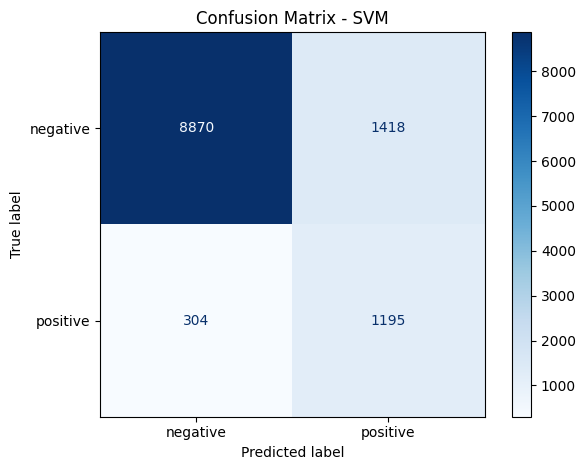

In [20]:
# Predict on test set
y_pred = model.predict(X_test_tfidf)

# Confusion matrix using encoded integer labels
cm = confusion_matrix(y_test_encoded, y_pred)

# Display with original class names
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - SVM")
plt.grid(False)
plt.tight_layout()
plt.show()

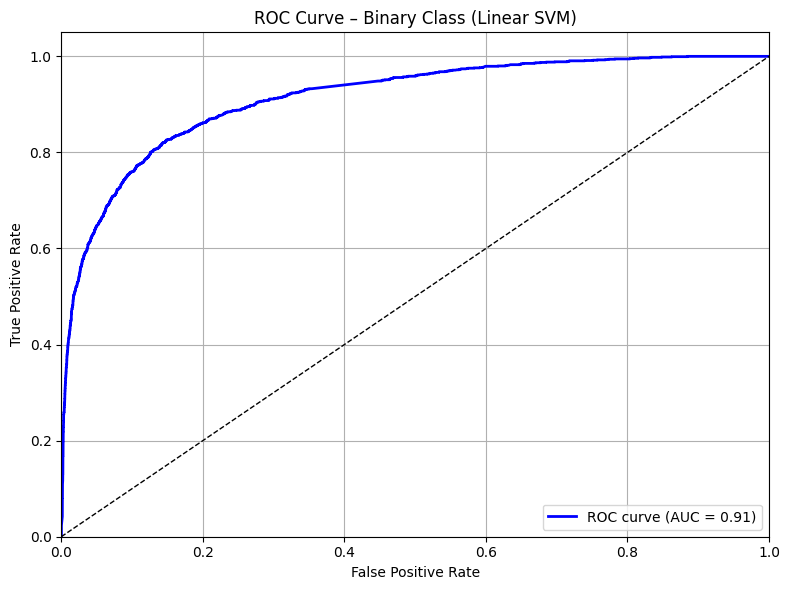

In [21]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Step 1: Wrap LinearSVC with CalibratedClassifierCV
base_svc = LinearSVC(class_weight='balanced', max_iter=10000, dual='auto')
calibrated_svc = CalibratedClassifierCV(base_svc, method='sigmoid', cv=3)
calibrated_svc.fit(X_all, y_train_encoded)

# Step 2: Predict probabilities
y_score = calibrated_svc.predict_proba(X_test_tfidf)[:, 1]  # Probability for class 1

# Step 3: Compute ROC curve and AUC
fpr, tpr, _ = roc_curve(y_test_encoded, y_score)
roc_auc = auc(fpr, tpr)

# Step 4: Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve – Binary Class (Linear SVM)')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()


# Multinomial Naive-Bayes


🔁 Fold 1/5
✅ Accuracy: 0.8139
              precision    recall  f1-score   support

    negative       0.78      0.87      0.82      2399
    positive       0.85      0.76      0.80      2399

    accuracy                           0.81      4798
   macro avg       0.82      0.81      0.81      4798
weighted avg       0.82      0.81      0.81      4798


🔁 Fold 2/5
✅ Accuracy: 0.8151
              precision    recall  f1-score   support

    negative       0.78      0.87      0.82      2399
    positive       0.85      0.76      0.80      2399

    accuracy                           0.82      4798
   macro avg       0.82      0.82      0.81      4798
weighted avg       0.82      0.82      0.81      4798


🔁 Fold 3/5
✅ Accuracy: 0.8183
              precision    recall  f1-score   support

    negative       0.79      0.87      0.83      2399
    positive       0.85      0.77      0.81      2399

    accuracy                           0.82      4798
   macro avg       0.82      0.82  

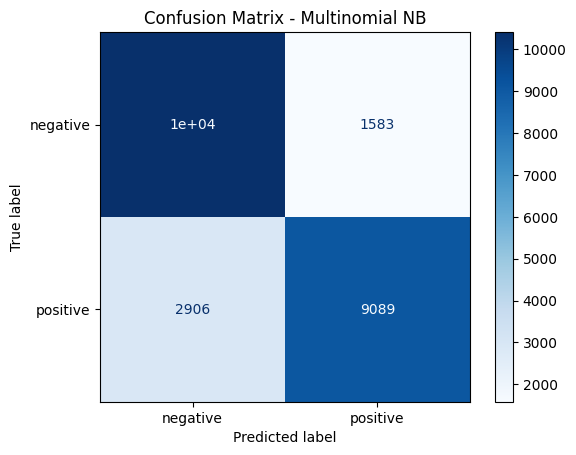

In [22]:
# Parameters
k = 5
skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

all_true = []
all_pred = []
all_prob = []

accuracies = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_all, y_train_bal)):
    print(f"\n🔁 Fold {fold + 1}/{k}")
    
    X_tr, X_val = X_all[train_idx], X_all[val_idx]
    y_tr, y_val = np.array(y_train_bal)[train_idx], np.array(y_train_bal)[val_idx]

    model = MultinomialNB()
    model.fit(X_tr, y_tr)

    y_pred = model.predict(X_val)
    y_proba = model.predict_proba(X_val)

    acc = accuracy_score(y_val, y_pred)
    accuracies.append(acc)
    print(f"✅ Accuracy: {acc:.4f}")
    print(classification_report(y_val, y_pred, target_names=label_encoder.classes_))

    all_true.extend(y_val)
    all_pred.extend(y_pred)
    all_prob.extend(y_proba)

# 🔷 Confusion Matrix
print("\n🧾 Confusion Matrix:")
cm = confusion_matrix(all_true, all_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - Multinomial NB")
plt.show()


## Bengali Dataset Classes and Loaders

In [23]:
# Dataset Class
class BengaliDataset(Dataset):
    def __init__(self, padded_sequences, labels):
        self.sequences = torch.tensor(padded_sequences, dtype=torch.long)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        return self.sequences[idx], self.labels[idx]

train_loader = DataLoader(BengaliDataset(X_train_pad, y_train_encoded), batch_size=64, shuffle=True)
val_loader = DataLoader(BengaliDataset(X_val_pad, y_val_encoded), batch_size=64)
test_loader = DataLoader(BengaliDataset(X_test_pad, y_test_encoded), batch_size=64)

In [24]:
# # 3. Load FastText Embeddings
# from gensim.models import KeyedVectors
# fasttext_model = KeyedVectors.load_word2vec_format("cc.bn.300.vec")

# fasttext_model.save("cc.bn.300_PN.kv")
# print("✅ FastText model saved in .kv format")

In [25]:
# Much faster than reloading .vec every time
from gensim.models import KeyedVectors
fasttext_model = KeyedVectors.load("cc.bn.300_PN.kv")

embedding_dim = 300
vocab_size = len(keras_tokenizer.word_index) + 1
embedding_matrix = np.zeros((vocab_size, embedding_dim))

for word, idx in keras_tokenizer.word_index.items():
    if word in fasttext_model:
        embedding_matrix[idx] = fasttext_model[word]
    else:
        embedding_matrix[idx] = np.random.normal(scale=0.6, size=(embedding_dim,))

# General Setup of CV(K-fold)

In [26]:
def run_kfold_cv(model_class, X, y, embedding_matrix=None, k=5, batch_size=64, epochs=5, model_save_dir="Bi-LSTM Models", test_loader=None):
    import os
    from sklearn.model_selection import StratifiedKFold
    from sklearn.metrics import accuracy_score, classification_report

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    all_fold_acc = []
    best_acc = 0.0
    best_model_path = os.path.join(model_save_dir, f"best_{model_save_dir}.pth")

    os.makedirs(model_save_dir, exist_ok=True)

    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
        print(f"\n🔁 Fold {fold + 1}/{k}")

        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        train_data = BengaliDataset(X_train, y_train)
        val_data = BengaliDataset(X_val, y_val)
        train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(val_data, batch_size=batch_size)

        model = model_class(embedding_matrix=embedding_matrix).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
        criterion = nn.CrossEntropyLoss()

        for epoch in range(epochs):
            model.train()
            total_loss = 0
            for inputs, labels in train_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                total_loss += loss.item()
            print(f"Epoch {epoch + 1} | Train Loss: {total_loss / len(train_loader):.4f}")

        model.eval()
        all_preds, all_labels = [], []
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                preds = model(inputs).argmax(dim=1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

        acc = accuracy_score(all_labels, all_preds)
        all_fold_acc.append(acc)
        print(f"✅ Fold {fold + 1} Accuracy: {acc:.4f}")
        print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_))

        if acc > best_acc:
            best_acc = acc
            torch.save(model.state_dict(), best_model_path)
            print("📦 Best model saved")

    print(f"\n📊 Average K-Fold Accuracy: {np.mean(all_fold_acc):.4f}")


# Bi-LSTM model

In [27]:
# 5. BiLSTM Model with Pretrained Embedding
class BiLSTMClassifier(nn.Module):
    def __init__(self, embedding_matrix, hidden_dim=128, output_dim=2, freeze=False):
        super(BiLSTMClassifier, self).__init__()
        num_embeddings, embedding_dim = embedding_matrix.shape
        self.embedding = nn.Embedding.from_pretrained(
            torch.tensor(embedding_matrix, dtype=torch.float32),
            freeze=freeze,
            padding_idx=0
        )
        self.bilstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, bidirectional=True, num_layers=2)
        self.dropout = nn.Dropout(0.5)
        self.fc1 = nn.Linear(hidden_dim * 2, 64)
        self.fc2 = nn.Linear(64, output_dim)

    def forward(self, x):
        x = self.embedding(x)
        _, (hidden, _) = self.bilstm(x)
        hidden_cat = torch.cat((hidden[-2], hidden[-1]), dim=1)
        x = self.dropout(hidden_cat)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

In [28]:
run_kfold_cv(
    model_class=lambda embedding_matrix: BiLSTMClassifier(
        embedding_matrix=embedding_matrix,
        hidden_dim=256,
        output_dim=2,   # or 3 for multi-class
        freeze=False
    ),
    X=X_np,
    y=y_np,
    embedding_matrix=embedding_matrix,
    k=5,
    batch_size=64,
    epochs=50,
    model_save_dir="Bi_LSTM_Models",
    test_loader=test_loader
)


🔁 Fold 1/5
Epoch 1 | Train Loss: 0.3063
Epoch 2 | Train Loss: 0.1086
Epoch 3 | Train Loss: 0.0466
Epoch 4 | Train Loss: 0.0266
Epoch 5 | Train Loss: 0.0192
Epoch 6 | Train Loss: 0.0131
Epoch 7 | Train Loss: 0.0083
Epoch 8 | Train Loss: 0.0065
Epoch 9 | Train Loss: 0.0115
Epoch 10 | Train Loss: 0.0116
Epoch 11 | Train Loss: 0.0048
Epoch 12 | Train Loss: 0.0018
Epoch 13 | Train Loss: 0.0009
Epoch 14 | Train Loss: 0.0010
Epoch 15 | Train Loss: 0.0006
Epoch 16 | Train Loss: 0.0007
Epoch 17 | Train Loss: 0.0006
Epoch 18 | Train Loss: 0.0005
Epoch 19 | Train Loss: 0.0007
Epoch 20 | Train Loss: 0.0006
Epoch 21 | Train Loss: 0.0006
Epoch 22 | Train Loss: 0.0006
Epoch 23 | Train Loss: 0.0006
Epoch 24 | Train Loss: 0.0006
Epoch 25 | Train Loss: 0.0005
Epoch 26 | Train Loss: 0.0006
Epoch 27 | Train Loss: 0.0052
Epoch 28 | Train Loss: 0.0269
Epoch 29 | Train Loss: 0.0061
Epoch 30 | Train Loss: 0.0027
Epoch 31 | Train Loss: 0.0007
Epoch 32 | Train Loss: 0.0006
Epoch 33 | Train Loss: 0.0007
Epoch 3

In [29]:
# ✅ Load and evaluate best model on test set
import os
best_model_path = "Bi_LSTM_Models/best_Bi_LSTM_Models.pth"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_class=lambda embedding_matrix: BiLSTMClassifier(
    embedding_matrix=embedding_matrix,
    hidden_dim=256,
    output_dim=2,   # or 3 for multi-class
    freeze=False
)

if os.path.exists(best_model_path):
    print(f"\n🔁 Loading best model from: {best_model_path}")
    best_model = model_class(embedding_matrix=embedding_matrix).to(device)
    best_model.load_state_dict(torch.load(best_model_path))

    if test_loader is not None:
        test_preds, test_labels = [], []
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = best_model(inputs)
                preds = torch.argmax(outputs, dim=1)
                test_preds.extend(preds.cpu().numpy())
                test_labels.extend(labels.cpu().numpy())

        print("\n🔍 Test Set Evaluation:")
        print(classification_report(test_labels, test_preds, target_names=label_encoder.classes_))
else:
    print("⚠️ No best model found to evaluate on test set.")


🔁 Loading best model from: Bi_LSTM_Models/best_Bi_LSTM_Models.pth

🔍 Test Set Evaluation:
              precision    recall  f1-score   support

    negative       0.98      0.93      0.95     10288
    positive       0.64      0.90      0.75      1499

    accuracy                           0.92     11787
   macro avg       0.81      0.91      0.85     11787
weighted avg       0.94      0.92      0.93     11787



In [30]:
# Load best model from the folder
best_model.load_state_dict(torch.load("Bi_LSTM_Models/best_Bi_LSTM_Models.pth"))
best_model.to(device)
best_model.eval()

BiLSTMClassifier(
  (embedding): Embedding(38575, 300, padding_idx=0)
  (bilstm): LSTM(300, 256, num_layers=2, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=512, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=2, bias=True)
)

In [31]:
# # 6. Train & Evaluate Model
# import os
# model = BiLSTMClassifier(embedding_matrix, hidden_dim=256, output_dim=2, freeze=False)
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# model.to(device)

# criterion = nn.CrossEntropyLoss()
# optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
# epochs = 30
# best_acc = 0.0

# os.makedirs("Bi-LSTM Models", exist_ok=True)

# for epoch in range(epochs):
#     model.train()
#     total_loss = 0
#     for inputs, labels in train_loader:
#         inputs, labels = inputs.to(device), labels.to(device)
#         optimizer.zero_grad()
#         outputs = model(inputs)
#         loss = criterion(outputs, labels)
#         loss.backward()
#         optimizer.step()
#         total_loss += loss.item()

#     print(f"Epoch {epoch+1} | Train Loss: {total_loss/len(train_loader):.4f}")

#     model.eval()
#     all_preds, all_labels = [], []
#     with torch.no_grad():
#         for inputs, labels in val_loader:
#             inputs, labels = inputs.to(device), labels.to(device)
#             outputs = model(inputs)
#             preds = torch.argmax(outputs, dim=1)
#             all_preds.extend(preds.cpu().numpy())
#             all_labels.extend(labels.cpu().numpy())

#     acc = accuracy_score(all_labels, all_preds)
#     print(f"Validation Accuracy: {acc:.4f}")
#     print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_))

#     if acc > best_acc:
#         best_acc = acc
#         torch.save(model.state_dict(), "Bi-LSTM Models/best_bilstm_model.pth")
#         print("✅ Best model saved")


In [32]:
# #7. Test set evaluation
# model.eval()
# test_preds, test_labels = [], []
# with torch.no_grad():
#     for inputs, labels in test_loader:
#         inputs, labels = inputs.to(device), labels.to(device)
#         outputs = model(inputs)
#         preds = torch.argmax(outputs, dim=1)
#         test_preds.extend(preds.cpu().numpy())
#         test_labels.extend(labels.cpu().numpy())

# print("🔍 Test Set Evaluation:")
# print(classification_report(test_labels, test_preds, target_names=label_encoder.classes_))


# CNN Text Classification with PyTorch – Full Pipeline

In [33]:
#2. CNN Model for Text Classification
class CNNTextClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, output_dim=2, kernel_sizes=[3,4,5], num_filters=100, dropout=0.5):
        super(CNNTextClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        self.convs = nn.ModuleList([
            nn.Conv2d(1, num_filters, (k, embedding_dim)) for k in kernel_sizes
        ])

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(num_filters * len(kernel_sizes), output_dim)

    def forward(self, x):
        embedded = self.embedding(x)              # (batch_size, seq_len, embed_dim)
        embedded = embedded.unsqueeze(1)          # (batch_size, 1, seq_len, embed_dim)

        conved = [F.relu(conv(embedded)).squeeze(3) for conv in self.convs]  # [(batch_size, num_filters, ~), ...]

        pooled = [F.max_pool1d(c, c.shape[2]).squeeze(2) for c in conved]   # [(batch_size, num_filters), ...]

        cat = torch.cat(pooled, dim=1)            # (batch_size, num_filters * len(kernel_sizes))
        return self.fc(self.dropout(cat))

In [34]:
run_kfold_cv(
    model_class=lambda embedding_matrix: CNNTextClassifier(vocab_size=len(keras_tokenizer.word_index) + 1, embedding_dim=300, output_dim=2),
    X=X_train_pad,
    y=y_train_encoded,
    embedding_matrix=None,  # CNN doesn't use pretrained FastText here
    k=5,
    batch_size=64,
    epochs=50,
    model_save_dir="CNN_Models",
    test_loader=test_loader
)



🔁 Fold 1/5
Epoch 1 | Train Loss: 0.3749
Epoch 2 | Train Loss: 0.1854
Epoch 3 | Train Loss: 0.1044
Epoch 4 | Train Loss: 0.0716
Epoch 5 | Train Loss: 0.0512
Epoch 6 | Train Loss: 0.0412
Epoch 7 | Train Loss: 0.0326
Epoch 8 | Train Loss: 0.0278
Epoch 9 | Train Loss: 0.0243
Epoch 10 | Train Loss: 0.0258
Epoch 11 | Train Loss: 0.0217
Epoch 12 | Train Loss: 0.0204
Epoch 13 | Train Loss: 0.0279
Epoch 14 | Train Loss: 0.0157
Epoch 15 | Train Loss: 0.0170
Epoch 16 | Train Loss: 0.0169
Epoch 17 | Train Loss: 0.0178
Epoch 18 | Train Loss: 0.0162
Epoch 19 | Train Loss: 0.0176
Epoch 20 | Train Loss: 0.0201
Epoch 21 | Train Loss: 0.0157
Epoch 22 | Train Loss: 0.0113
Epoch 23 | Train Loss: 0.0111
Epoch 24 | Train Loss: 0.0115
Epoch 25 | Train Loss: 0.0158
Epoch 26 | Train Loss: 0.0137
Epoch 27 | Train Loss: 0.0174
Epoch 28 | Train Loss: 0.0170
Epoch 29 | Train Loss: 0.0141
Epoch 30 | Train Loss: 0.0170
Epoch 31 | Train Loss: 0.0165
Epoch 32 | Train Loss: 0.0107
Epoch 33 | Train Loss: 0.0134
Epoch 3

In [35]:
# ✅ Load and evaluate best model on test set
import os
best_model_path = "CNN_Models/best_CNN_Models.pth"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_class=lambda embedding_matrix: CNNTextClassifier(vocab_size=len(keras_tokenizer.word_index) + 1, embedding_dim=300, output_dim=2)

if os.path.exists(best_model_path):
    print(f"\n🔁 Loading best model from: {best_model_path}")
    best_model = model_class(embedding_matrix=embedding_matrix).to(device)
    best_model.load_state_dict(torch.load(best_model_path))

    if test_loader is not None:
        test_preds, test_labels = [], []
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = best_model(inputs)
                preds = torch.argmax(outputs, dim=1)
                test_preds.extend(preds.cpu().numpy())
                test_labels.extend(labels.cpu().numpy())

        print("\n🔍 Test Set Evaluation:")
        print(classification_report(test_labels, test_preds, target_names=label_encoder.classes_))
else:
    print("⚠️ No best model found to evaluate on test set.")


🔁 Loading best model from: CNN_Models/best_CNN_Models.pth

🔍 Test Set Evaluation:
              precision    recall  f1-score   support

    negative       0.99      0.92      0.95     10288
    positive       0.61      0.91      0.73      1499

    accuracy                           0.91     11787
   macro avg       0.80      0.91      0.84     11787
weighted avg       0.94      0.91      0.92     11787



In [37]:
# Load best CNN model
best_model.load_state_dict(torch.load("CNN_Models/best_CNN_Models.pth"))
best_model.to(device)
best_model.eval()


CNNTextClassifier(
  (embedding): Embedding(38575, 300, padding_idx=0)
  (convs): ModuleList(
    (0): Conv2d(1, 100, kernel_size=(3, 300), stride=(1, 1))
    (1): Conv2d(1, 100, kernel_size=(4, 300), stride=(1, 1))
    (2): Conv2d(1, 100, kernel_size=(5, 300), stride=(1, 1))
  )
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=300, out_features=2, bias=True)
)

In [36]:
# #4. Training & Validation Loop
# import os
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# vocab_size = len(keras_tokenizer.word_index) + 1
# model = CNNTextClassifier(vocab_size=vocab_size).to(device)

# criterion = nn.CrossEntropyLoss()
# optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
# epochs = 30
# best_acc = 0.0
# os.makedirs("CNN Models", exist_ok=True)

# for epoch in range(epochs):
#     model.train()
#     total_loss = 0
#     for inputs, labels in train_loader:
#         inputs, labels = inputs.to(device), labels.to(device)
#         optimizer.zero_grad()
#         outputs = model(inputs)
#         loss = criterion(outputs, labels)
#         loss.backward()
#         optimizer.step()
#         total_loss += loss.item()

#     print(f"Epoch {epoch+1} | Train Loss: {total_loss/len(train_loader):.4f}")

#     # Validation
#     model.eval()
#     val_preds, val_labels = [], []
#     with torch.no_grad():
#         for inputs, labels in val_loader:
#             inputs, labels = inputs.to(device), labels.to(device)
#             outputs = model(inputs)
#             preds = torch.argmax(outputs, dim=1)
#             val_preds.extend(preds.cpu().numpy())
#             val_labels.extend(labels.cpu().numpy())

#     acc = accuracy_score(val_labels, val_preds)
#     print(f"Validation Accuracy: {acc:.4f}")
#     print(classification_report(val_labels, val_preds, target_names=label_encoder.classes_))

#     if acc > best_acc:
#         best_acc = acc
#         save_path = os.path.join("CNN Models", "best_cnn_model.pth")
#         torch.save(model.state_dict(), save_path)
#         print("✅ Best CNN model saved!")


# Pipeline for CNN + Bi-LSTM Hybrid (PyTorch)

In [30]:
#1. Model Definition
class CNN_BiLSTM_Hybrid(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128, output_dim=2, dropout=0.5, embedding_weights=None):
        super(CNN_BiLSTM_Hybrid, self).__init__()

        if embedding_weights is not None:
            self.embedding = nn.Embedding.from_pretrained(
                torch.tensor(embedding_weights, dtype=torch.float32),
                freeze=True,
                padding_idx=0
            )
        else:
            self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        self.conv1 = nn.Conv1d(in_channels=embedding_dim, out_channels=128, kernel_size=5)
        self.pool = nn.MaxPool1d(kernel_size=2)

        self.bilstm = nn.LSTM(input_size=128, hidden_size=hidden_dim, batch_first=True, bidirectional=True)

        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden_dim * 2, 64)
        self.fc2 = nn.Linear(64, output_dim)

    def forward(self, x):
        x = self.embedding(x)                      # (batch_size, seq_len, embedding_dim)
        x = x.permute(0, 2, 1)                     # (batch_size, embedding_dim, seq_len) for Conv1D
        x = F.relu(self.conv1(x))                 # (batch_size, out_channels, new_seq_len)
        x = self.pool(x)                          # (batch_size, out_channels, pooled_len)
        x = x.permute(0, 2, 1)                    # (batch_size, pooled_len, out_channels)
        _, (hidden, _) = self.bilstm(x)           # hidden: (2, batch, hidden_dim)
        hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)  # (batch_size, hidden_dim*2)
        x = self.dropout(hidden)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

In [31]:
run_kfold_cv(
    model_class=lambda embedding_matrix: CNN_BiLSTM_Hybrid(
        vocab_size=embedding_matrix.shape[0],
        embedding_dim=embedding_matrix.shape[1],
        hidden_dim=256,
        output_dim=2,
        embedding_weights=embedding_matrix
    ),
    X=X_train_pad,
    y=y_train_encoded,
    embedding_matrix=embedding_matrix,
    k=5,
    batch_size=64,
    epochs=50,
    model_save_dir="CNN_BiLSTM_Models",
    test_loader=test_loader
)



🔁 Fold 1/5
Epoch 1 | Train Loss: 0.4592
Epoch 2 | Train Loss: 0.2961
Epoch 3 | Train Loss: 0.2227
Epoch 4 | Train Loss: 0.1670
Epoch 5 | Train Loss: 0.1271
Epoch 6 | Train Loss: 0.0990
Epoch 7 | Train Loss: 0.0795
Epoch 8 | Train Loss: 0.0612
Epoch 9 | Train Loss: 0.0498
Epoch 10 | Train Loss: 0.0482
Epoch 11 | Train Loss: 0.0393
Epoch 12 | Train Loss: 0.0354
Epoch 13 | Train Loss: 0.0346
Epoch 14 | Train Loss: 0.0227
Epoch 15 | Train Loss: 0.0230
Epoch 16 | Train Loss: 0.0228
Epoch 17 | Train Loss: 0.0189
Epoch 18 | Train Loss: 0.0278
Epoch 19 | Train Loss: 0.0234
Epoch 20 | Train Loss: 0.0189
Epoch 21 | Train Loss: 0.0198
Epoch 22 | Train Loss: 0.0175
Epoch 23 | Train Loss: 0.0143
Epoch 24 | Train Loss: 0.0186
Epoch 25 | Train Loss: 0.0194
Epoch 26 | Train Loss: 0.0166
Epoch 27 | Train Loss: 0.0127
Epoch 28 | Train Loss: 0.0180
Epoch 29 | Train Loss: 0.0170
Epoch 30 | Train Loss: 0.0145
Epoch 31 | Train Loss: 0.0140
Epoch 32 | Train Loss: 0.0125
Epoch 33 | Train Loss: 0.0145
Epoch 3

In [32]:
# ✅ Load and evaluate best model on test set
import os
best_model_path = "CNN_BiLSTM_Models/best_CNN_BiLSTM_Models.pth"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_class=lambda embedding_matrix: CNN_BiLSTM_Hybrid(
    vocab_size=embedding_matrix.shape[0],
    embedding_dim=embedding_matrix.shape[1],
    hidden_dim=256,
    output_dim=2,
    embedding_weights=embedding_matrix
)

if os.path.exists(best_model_path):
    print(f"\n🔁 Loading best model from: {best_model_path}")
    best_model = model_class(embedding_matrix=embedding_matrix).to(device)
    best_model.load_state_dict(torch.load(best_model_path))

    if test_loader is not None:
        test_preds, test_labels = [], []
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = best_model(inputs)
                preds = torch.argmax(outputs, dim=1)
                test_preds.extend(preds.cpu().numpy())
                test_labels.extend(labels.cpu().numpy())

        print("\n🔍 Test Set Evaluation:")
        print(classification_report(test_labels, test_preds, target_names=label_encoder.classes_))
else:
    print("⚠️ No best model found to evaluate on test set.")


🔁 Loading best model from: CNN_BiLSTM_Models/best_CNN_BiLSTM_Models.pth

🔍 Test Set Evaluation:
              precision    recall  f1-score   support

    negative       0.98      0.88      0.93     10288
    positive       0.52      0.89      0.65      1499

    accuracy                           0.88     11787
   macro avg       0.75      0.88      0.79     11787
weighted avg       0.92      0.88      0.89     11787



In [34]:
# Load best CNN BiLSTM model
best_model.load_state_dict(torch.load("CNN_BiLSTM_Models/best_CNN_BiLSTM_Models.pth"))
best_model.to(device)
best_model.eval()


CNN_BiLSTM_Hybrid(
  (embedding): Embedding(38575, 300, padding_idx=0)
  (conv1): Conv1d(300, 128, kernel_size=(5,), stride=(1,))
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (bilstm): LSTM(128, 256, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=512, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=2, bias=True)
)

In [33]:
# #5. Training + Validation Loop
# import os
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# vocab_size = len(keras_tokenizer.word_index) + 1
# model = CNN_BiLSTM_Hybrid(vocab_size).to(device)

# criterion = nn.CrossEntropyLoss()
# optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
# epochs = 30
# best_acc = 0.0
# os.makedirs("CNN_BiLSTM_Models", exist_ok=True)

# for epoch in range(epochs):
#     model.train()
#     total_loss = 0
#     for inputs, labels in train_loader:
#         inputs, labels = inputs.to(device), labels.to(device)
#         optimizer.zero_grad()
#         outputs = model(inputs)
#         loss = criterion(outputs, labels)
#         loss.backward()
#         optimizer.step()
#         total_loss += loss.item()

#     print(f"Epoch {epoch+1} | Train Loss: {total_loss/len(train_loader):.4f}")

#     # Validation
#     model.eval()
#     val_preds, val_labels = [], []
#     with torch.no_grad():
#         for inputs, labels in val_loader:
#             inputs, labels = inputs.to(device), labels.to(device)
#             outputs = model(inputs)
#             preds = torch.argmax(outputs, dim=1)
#             val_preds.extend(preds.cpu().numpy())
#             val_labels.extend(labels.cpu().numpy())

#     acc = accuracy_score(val_labels, val_preds)
#     print(f"Validation Accuracy: {acc:.4f}")
#     print(classification_report(val_labels, val_preds, target_names=label_encoder.classes_))

#     if acc > best_acc:
#         best_acc = acc
#         save_path = os.path.join("CNN_BiLSTM_Models", "best_cnn_bilstm_model.pth")
#         torch.save(model.state_dict(), save_path)
#         print("✅ Best hybrid model saved.")

# Bi-LSTM + Attention Model in Keras

In [35]:
#1. Model Definition (Bi-LSTM + Attention)
class BiLSTM_Attention(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128, output_dim=2, dropout=0.5, embedding_weights=None):
        super(BiLSTM_Attention, self).__init__()

        if embedding_weights is not None:
            self.embedding = nn.Embedding.from_pretrained(
                torch.tensor(embedding_weights, dtype=torch.float32),
                freeze=True,
                padding_idx=0
            )
        else:
            self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        self.bilstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.attention = nn.Linear(hidden_dim * 2, 1)
        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden_dim * 2, 64)
        self.fc2 = nn.Linear(64, output_dim)

    def forward(self, x):
        embedded = self.embedding(x)                       # (batch_size, seq_len, embedding_dim)
        lstm_out, _ = self.bilstm(embedded)                # (batch_size, seq_len, hidden_dim*2)

        # Attention weights
        attn_weights = torch.tanh(self.attention(lstm_out))  # (batch_size, seq_len, 1)
        attn_weights = torch.softmax(attn_weights, dim=1)    # normalize across seq_len

        # Context vector
        context = torch.sum(attn_weights * lstm_out, dim=1)  # (batch_size, hidden_dim*2)

        x = self.dropout(context)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

In [36]:
run_kfold_cv(
    model_class=lambda embedding_matrix: BiLSTM_Attention(
        vocab_size=len(keras_tokenizer.word_index) + 1,
        embedding_dim=300,
        hidden_dim=256,
        output_dim=2,
        embedding_weights=embedding_matrix
    ),
    X=X_train_pad,
    y=y_train_encoded,
    embedding_matrix=embedding_matrix,
    k=5,
    batch_size=64,
    epochs=50,
    model_save_dir="BiLSTM_Attention_Models",
    test_loader=test_loader
)



🔁 Fold 1/5
Epoch 1 | Train Loss: 0.6121
Epoch 2 | Train Loss: 0.4452
Epoch 3 | Train Loss: 0.3416
Epoch 4 | Train Loss: 0.2717
Epoch 5 | Train Loss: 0.2234
Epoch 6 | Train Loss: 0.1887
Epoch 7 | Train Loss: 0.1628
Epoch 8 | Train Loss: 0.1444
Epoch 9 | Train Loss: 0.1270
Epoch 10 | Train Loss: 0.1124
Epoch 11 | Train Loss: 0.1021
Epoch 12 | Train Loss: 0.0905
Epoch 13 | Train Loss: 0.0785
Epoch 14 | Train Loss: 0.0686
Epoch 15 | Train Loss: 0.0629
Epoch 16 | Train Loss: 0.0611
Epoch 17 | Train Loss: 0.0530
Epoch 18 | Train Loss: 0.0433
Epoch 19 | Train Loss: 0.0537
Epoch 20 | Train Loss: 0.0382
Epoch 21 | Train Loss: 0.0386
Epoch 22 | Train Loss: 0.0351
Epoch 23 | Train Loss: 0.0256
Epoch 24 | Train Loss: 0.0300
Epoch 25 | Train Loss: 0.0352
Epoch 26 | Train Loss: 0.0259
Epoch 27 | Train Loss: 0.0328
Epoch 28 | Train Loss: 0.0241
Epoch 29 | Train Loss: 0.0182
Epoch 30 | Train Loss: 0.0187
Epoch 31 | Train Loss: 0.0223
Epoch 32 | Train Loss: 0.0219
Epoch 33 | Train Loss: 0.0133
Epoch 3

In [37]:
# ✅ Load and evaluate best model on test set
import os
best_model_path = "BiLSTM_Attention_Models/best_BiLSTM_Attention_Models.pth"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_class=lambda embedding_matrix: BiLSTM_Attention(
    vocab_size=len(keras_tokenizer.word_index) + 1,
    embedding_dim=300,
    hidden_dim=256,
    output_dim=2,
    embedding_weights=embedding_matrix
)

if os.path.exists(best_model_path):
    print(f"\n🔁 Loading best model from: {best_model_path}")
    best_model = model_class(embedding_matrix=embedding_matrix).to(device)
    best_model.load_state_dict(torch.load(best_model_path))

    if test_loader is not None:
        test_preds, test_labels = [], []
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = best_model(inputs)
                preds = torch.argmax(outputs, dim=1)
                test_preds.extend(preds.cpu().numpy())
                test_labels.extend(labels.cpu().numpy())

        print("\n🔍 Test Set Evaluation:")
        print(classification_report(test_labels, test_preds, target_names=label_encoder.classes_))
else:
    print("⚠️ No best model found to evaluate on test set.")


🔁 Loading best model from: BiLSTM_Attention_Models/best_BiLSTM_Attention_Models.pth

🔍 Test Set Evaluation:
              precision    recall  f1-score   support

    negative       0.98      0.91      0.94     10288
    positive       0.58      0.89      0.70      1499

    accuracy                           0.90     11787
   macro avg       0.78      0.90      0.82     11787
weighted avg       0.93      0.90      0.91     11787



In [39]:
# Load best BiLSTM Attention model
best_model.load_state_dict(torch.load("BiLSTM_Attention_Models/best_BiLSTM_Attention_Models.pth"))
best_model.to(device)
best_model.eval()


BiLSTM_Attention(
  (embedding): Embedding(38575, 300, padding_idx=0)
  (bilstm): LSTM(300, 256, batch_first=True, bidirectional=True)
  (attention): Linear(in_features=512, out_features=1, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=512, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=2, bias=True)
)

In [38]:
# #5. Training + Validation Loop
# import os
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# vocab_size = len(keras_tokenizer.word_index) + 1
# model = BiLSTM_Attention(vocab_size).to(device)

# criterion = nn.CrossEntropyLoss()
# optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
# epochs = 30
# best_acc = 0.0
# os.makedirs("BiLSTM_Attention_Models", exist_ok=True)

# for epoch in range(epochs):
#     model.train()
#     total_loss = 0
#     for inputs, labels in train_loader:
#         inputs, labels = inputs.to(device), labels.to(device)
#         optimizer.zero_grad()
#         outputs = model(inputs)
#         loss = criterion(outputs, labels)
#         loss.backward()
#         optimizer.step()
#         total_loss += loss.item()

#     print(f"Epoch {epoch+1} | Train Loss: {total_loss/len(train_loader):.4f}")

#     # Validation
#     model.eval()
#     val_preds, val_labels = [], []
#     with torch.no_grad():
#         for inputs, labels in val_loader:
#             inputs, labels = inputs.to(device), labels.to(device)
#             outputs = model(inputs)
#             preds = torch.argmax(outputs, dim=1)
#             val_preds.extend(preds.cpu().numpy())
#             val_labels.extend(labels.cpu().numpy())

#     acc = accuracy_score(val_labels, val_preds)
#     print(f"Validation Accuracy: {acc:.4f}")
#     print(classification_report(val_labels, val_preds, target_names=label_encoder.classes_))

#     if acc > best_acc:
#         best_acc = acc
#         torch.save(model.state_dict(), os.path.join("BiLSTM_Attention_Models", "best_bilstm_attention_model.pth"))
#         print("✅ Best attention model saved.")

# An BERT + CNN + Bi-LSTM Hybrid Model (PyTorch)

In [60]:
def run_bert_kfold_cv(model_class, texts, labels, model_save_dir="BERT_CNN_LSTM_CV_Models",
                      tokenizer_name='bert-base-multilingual-cased', max_len=100,
                      k=5, batch_size=16, epochs=5, test_loader=None):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    os.makedirs(model_save_dir, exist_ok=True)

    tokenizer = AutoTokenizer.from_pretrained(tokenizer_name)
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

    all_fold_acc = []
    best_acc = 0.0
    best_model_path = os.path.join(model_save_dir, f"best_{model_save_dir.replace(' ', '_')}.pth")

    for fold, (train_idx, val_idx) in enumerate(skf.split(texts, labels)):
        print(f"\n🔁 Fold {fold + 1}/{k}")

        X_train, X_val = np.array(texts)[train_idx], np.array(texts)[val_idx]
        y_train, y_val = np.array(labels)[train_idx], np.array(labels)[val_idx]

        train_dataset = BERTDataset(X_train, y_train, tokenizer, max_len)
        val_dataset   = BERTDataset(X_val, y_val, tokenizer, max_len)
        train_loader  = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        val_loader    = DataLoader(val_dataset, batch_size=batch_size)

        model = model_class().to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=2e-5)
        criterion = torch.nn.CrossEntropyLoss()

        for epoch in range(epochs):
            model.train()
            total_loss = 0
            for batch in train_loader:
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                labels = batch['labels'].to(device)

                optimizer.zero_grad()
                outputs = model(input_ids, attention_mask)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                total_loss += loss.item()

            print(f"Epoch {epoch + 1} | Train Loss: {total_loss / len(train_loader):.4f}")

        # Validation
        model.eval()
        all_preds, all_labels = [], []
        with torch.no_grad():
            for batch in val_loader:
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                labels = batch['labels'].to(device)
                outputs = model(input_ids, attention_mask)
                preds = torch.argmax(outputs, dim=1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

        acc = accuracy_score(all_labels, all_preds)
        all_fold_acc.append(acc)
        print(f"✅ Fold {fold + 1} Accuracy: {acc:.4f}")
        print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_))

        if acc > best_acc:
            best_acc = acc
            torch.save(model.state_dict(), best_model_path)
            print("📦 Best model updated")

    print(f"\n📊 Average K-Fold Accuracy: {np.mean(all_fold_acc):.4f}")


In [61]:
#2. Dataset Class
class BERTDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=100):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        encoding = self.tokenizer.encode_plus(
            text,
            add_special_tokens=True,
            max_length=self.max_len,
            truncation=True,
            padding='max_length',
            return_tensors='pt',
            return_attention_mask=True
        )
        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long)
        }


In [62]:
# #3. Prepare Dataloaders

# tokenizer = AutoTokenizer.from_pretrained('bert-base-multilingual-cased')

# train_dataset = BERTDataset(X_train_bal_clean, y_train_encoded, tokenizer)
# val_dataset   = BERTDataset(X_val_clean, y_val_encoded, tokenizer)
# test_dataset  = BERTDataset(X_test_clean, y_test_encoded, tokenizer)

# train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
# val_loader   = DataLoader(val_dataset, batch_size=16)
# test_loader  = DataLoader(test_dataset, batch_size=16)


In [63]:
#1. Model Definition (BERT + CNN + Bi-LSTM)
class BERT_CNN_LSTM(nn.Module):
    def __init__(self, bert_model_name='bert-base-multilingual-cased', hidden_dim=256, output_dim=2, dropout=0.5):
        super(BERT_CNN_LSTM, self).__init__()
        
        self.bert = AutoModel.from_pretrained(bert_model_name)
        self.conv1 = nn.Conv1d(in_channels=self.bert.config.hidden_size, out_channels=128, kernel_size=3, padding=1)
        self.lstm = nn.LSTM(input_size=128, hidden_size=hidden_dim, batch_first=True, bidirectional=True)
        
        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden_dim * 2, 64)
        self.fc2 = nn.Linear(64, output_dim)

    def forward(self, input_ids, attention_mask):
        with torch.no_grad():  # Freeze BERT if needed for faster training
            bert_outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        
        last_hidden_state = bert_outputs.last_hidden_state  # (batch_size, seq_len, hidden_size)
        
        x = last_hidden_state.permute(0, 2, 1)  # (batch_size, hidden_size, seq_len) for CNN
        x = F.relu(self.conv1(x))               # (batch_size, 128, seq_len)
        x = x.permute(0, 2, 1)                  # (batch_size, seq_len, 128) for LSTM
        lstm_out, _ = self.lstm(x)              # (batch_size, seq_len, hidden_dim*2)
        pooled = torch.mean(lstm_out, dim=1)    # (batch_size, hidden_dim*2)
        
        x = self.dropout(pooled)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

In [64]:
# Ensure texts are a NumPy array of strings (on CPU)
if isinstance(X_train_bal_clean, torch.Tensor):
    X_train_bal_clean = X_train_bal_clean.cpu().numpy()
else:
    X_train_bal_clean = np.array(X_train_bal_clean)

# Ensure labels are a NumPy array of integers (on CPU)
if isinstance(y_train_encoded, torch.Tensor):
    y_train_encoded = y_train_encoded.cpu().numpy()
else:
    y_train_encoded = np.array(y_train_encoded)
    
run_bert_kfold_cv(
    model_class=BERT_CNN_LSTM,
    texts=X_train_bal_clean,
    labels=y_train_encoded,
    model_save_dir="BERT_CNN_LSTM_Models",
    max_len=10,
    k=2,
    batch_size=16,
    epochs=1
)


🔁 Fold 1/2


AttributeError: 'numpy.ndarray' object has no attribute 'device'

In [ ]:
# ✅ Load and evaluate best model on test set
import os
best_model_path = "BERT_CNN_LSTM_Models/best_BERT_CNN_LSTM_Models.pth"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_class=BERT_CNN_LSTM

if os.path.exists(best_model_path):
    print(f"\n🔁 Loading best model from: {best_model_path}")
    best_model = model_class(embedding_matrix=embedding_matrix).to(device)
    best_model.load_state_dict(torch.load(best_model_path))

    if test_loader is not None:
        test_preds, test_labels = [], []
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = best_model(inputs)
                preds = torch.argmax(outputs, dim=1)
                test_preds.extend(preds.cpu().numpy())
                test_labels.extend(labels.cpu().numpy())

        print("\n🔍 Test Set Evaluation:")
        print(classification_report(test_labels, test_preds, target_names=label_encoder.classes_))
else:
    print("⚠️ No best model found to evaluate on test set.")

In [ ]:
# #5. Training + Validation Loop
# import os
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# model = BERT_CNN_LSTM().to(device)

# criterion = nn.CrossEntropyLoss()
# optimizer = torch.optim.Adam(model.parameters(), lr=2e-5)
# epochs = 30
# best_acc = 0.0
# os.makedirs("BERT_CNN_LSTM_Models", exist_ok=True)

# for epoch in range(epochs):
#     model.train()
#     total_loss = 0
#     for batch in train_loader:
#         input_ids = batch['input_ids'].to(device)
#         attention_mask = batch['attention_mask'].to(device)
#         labels = batch['labels'].to(device)

#         optimizer.zero_grad()
#         outputs = model(input_ids, attention_mask)
#         loss = criterion(outputs, labels)
#         loss.backward()
#         optimizer.step()
#         total_loss += loss.item()
    
#     print(f"Epoch {epoch+1} | Train Loss: {total_loss/len(train_loader):.4f}")

#     # Validation
#     model.eval()
#     all_preds, all_labels = [], []
#     with torch.no_grad():
#         for batch in val_loader:
#             input_ids = batch['input_ids'].to(device)
#             attention_mask = batch['attention_mask'].to(device)
#             labels = batch['labels'].to(device)
#             outputs = model(input_ids, attention_mask)
#             preds = torch.argmax(outputs, dim=1)
#             all_preds.extend(preds.cpu().numpy())
#             all_labels.extend(labels.cpu().numpy())

#     acc = accuracy_score(all_labels, all_preds)
#     print(f"Validation Accuracy: {acc:.4f}")
#     print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_))

#     # Save best model
#     if acc > best_acc:
#         best_acc = acc
#         torch.save(model.state_dict(), "best_bert_cnn_lstm_model.pth")
#         print("✅ Saved best BERT+CNN+LSTM model.")

In [ ]:
best_model.load_state_dict(torch.load("best_BERT_CNN_LSTM_Models.pth"))
best_model.to(device)
best_model.eval()
